# ARM KAZR Cloud Persistence Project: Target Sketch & Cloud State Testing

**Alec Blevins — STA 496, Fall 2026**

## Purpose

This will be a smaller notebook derived to: 

1. **Validate** the new `src/cloud_state.py` against the 3-day numbers already in `03_cloud_state.ipynb` and `04_temporal_dynamics.ipynb`. 
2. **Sketch two target definitions** on QC-processed days at several candidate horizons, and report class balance and row exclusions. 

**This notebook is not the builder**. No features, no model, no leakage tests. The point is to pick a target semantic before writing `targets.py` and `build_dataset.py`. 

The 3-day sample is a **pipeline test**, not an estimate of 2024 class balance. Jan 1-2 are dominated by multi-hour cloudy runs; Jan 3 is mostly clear. 


## 1. Imports & Paths

In [1]:
##################
##Library Import##
##################

from pathlib import Path
import sys

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display

##############
##Path Setup##
##############

_start = Path.cwd().resolve()

PROJECT_ROOT = next(
    (c for c in [_start, *_start.parents]
     if (c / "ARM_DATA" / "2024-2025").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook from inside the project.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

#Import src functions
from src.qc import apply_qc
from src.cloud_state import (
    construct_cloud_state,
    concat_cloud_state_frames,
    segment_runs,
    summarize_run_durations,
)

QC_DATA_DIR = ( #Establish QC root
    PROJECT_ROOT / "ARM_DATA" / "2024-2025" / "qc" / "sgparsclkazr1kolliasC1.c0"
)
TEST_DATES = ["20240101", "20240102", "20240103"] #Test files
QC_FILES = {d: QC_DATA_DIR / f"kazr_{d}.nc" for d in TEST_DATES} #Map test dates to QC files

#Check that all QC files exist
for p in QC_FILES.values():
    if not p.is_file():
        raise FileNotFoundError(p)

print("Project root:", PROJECT_ROOT)
print("QC files:")
for d, p in QC_FILES.items():
    print(f"  {d}: {p.name}")

Project root: C:\Users\alecp\MyPrograms\STA 496\ARM_Cloud_Modeling
QC files:
  20240101: kazr_20240101.nc
  20240102: kazr_20240102.nc
  20240103: kazr_20240103.nc


## 1. Validation of `construct_cloud_state` and `segment_runs`

We expect these numbers (from `cloud_state.ipynb`): 

| Date | Cloudy | Clear | Unknown |
|---|---:|---:|---:|
| 2024-01-01 | 20,820 | 780 | 0 |
| 2024-01-02 | 20,596 | 1,004 | 0 |
| 2024-01-03 | 3,075 | 18,525 | 0 |
| 3-day total | 44,491 | 20,309 | 0 |

And 69 known-state runs total (35 clear, 34 cloudy) with clear median ≈ 5.47 min and cloudy median ≈ 4.43 min (from `04_temporal_dynamics.ipynb`).


In [2]:
frames = []

#Process each QC file and construct cloud state frames
for date, path in QC_FILES.items():
    with xr.open_dataset(path) as ds:
        qc_ds = apply_qc(ds)                     #refreshes kazr_available, reapply QC because why not
        frame = construct_cloud_state(qc_ds)     # Construct cloud state
        frame["source_date"] = date
        frames.append(frame)

cloud_state_df = concat_cloud_state_frames(frames) #Concatentate all frames

print(f"Rows: {len(cloud_state_df):,}")
print(f"Range: {cloud_state_df.index.min()} to {cloud_state_df.index.max()}")

# Daily counts
daily = (
    cloud_state_df.groupby("source_date")["cloud_state"]
    .value_counts()
    .unstack(fill_value=0)
    .rename(columns={1: "Cloudy", 0: "Clear", -1: "Unknown"})
    .reindex(columns=["Cloudy", "Clear", "Unknown"], fill_value=0)
)

#Daily cloud fraction
daily["cloud_fraction"] = daily["Cloudy"] / (daily["Cloudy"] + daily["Clear"])
display(daily)

# Assert against nb 03
expected = {
    "20240101": (20_820,   780, 0),
    "20240102": (20_596, 1_004, 0),
    "20240103": ( 3_075, 18_525, 0),
}
for date, (nc, ncl, nu) in expected.items():
    row = daily.loc[date]
    assert row["Cloudy"] == nc and row["Clear"] == ncl and row["Unknown"] == nu, \
        f"{date} counts differ: got {row.to_dict()}, expected {(nc, ncl, nu)}"
assert daily[["Cloudy", "Clear", "Unknown"]].sum().tolist() == [44_491, 20_309, 0]

print("\n[OK] daily counts match nb 03")

Rows: 64,800
Range: 2024-01-01 00:00:00 to 2024-01-03 23:59:56


cloud_state,Cloudy,Clear,Unknown,cloud_fraction
source_date,,,,
20240101,20820,780,0,0.963889
20240102,20596,1004,0,0.953519
20240103,3075,18525,0,0.142361



[OK] daily counts match nb 03


In [3]:
#Now validating runs
runs = segment_runs(cloud_state_df) #Call run function
print(f"Total known-state runs: {len(runs)}")
print(f"  Clear:  {int((runs['cloud_state'] == 0).sum())}")
print(f"  Cloudy: {int((runs['cloud_state'] == 1).sum())}")

display(summarize_run_durations(runs).round(2))

# Assert against nb 04
assert len(runs) == 69
assert int((runs["cloud_state"] == 0).sum()) == 35
assert int((runs["cloud_state"] == 1).sum()) == 34
assert abs(runs.loc[runs["state_label"] == "Clear",  "sample_duration_minutes"].median() - 5.4667) < 1e-3
assert abs(runs.loc[runs["state_label"] == "Cloudy", "sample_duration_minutes"].median() - 4.4333) < 1e-3

print("\n[OK] run counts and medians match nb 04")

Total known-state runs: 69
  Clear:  35
  Cloudy: 34


,n_runs,mean_minutes,median_minutes,p25_minutes,p75_minutes,p90_minutes,maximum_minutes
state,,,,,,,
Clear,35,38.68,5.47,1.87,22.40,62.45,636.53
Cloudy,34,87.24,4.43,1.47,20.48,117.04,1225.00



[OK] run counts and medians match nb 04


## 2. Aggregation to 20-second bins

The aggregation src module isn't written yet, so this cell will do it using the same convention as `05_annual_temporal_dynamics.ipynb`. When we build `aggregation.py`, this cell will call that. 

Bin state rule: 
- If the bin is not fully observed or not fully known → **unknown**.
- Otherwise, cloud fraction `> 0.5` → **cloudy**; `< 0.5` → **clear**; `== 0.5` → **unknown** (tie).


In [4]:
#Building 20 second bins
INTERVAL = "20s"
INTERVAL_SECONDS = 20
EXPECTED_STEP_SECONDS = 4

#Function for bin aggregation of cloud state data
def aggregate_to_bins(state_df, interval=INTERVAL):
    state = state_df["cloud_state"]
    known   = state.isin([0, 1]).astype(np.int8) # 1 if cloud state is known (0 or 1)
    cloudy  = state.eq(1).astype(np.int8) # 1 if cloud state is cloudy, 0 otherwise
    obs_one = pd.Series(1, index=state.index, dtype=np.int8) # 1 for every observation, used to count total observations per bin
    kwargs = dict(origin="start_day", label="left", closed="left") # Resampling parameters for bin aggregation

    known_count    = known.resample(interval, **kwargs).sum() # Count of known cloud state observations per bin
    cloudy_count   = cloudy.resample(interval, **kwargs).sum() # Count of cloudy observations per bin
    observed_count = obs_one.resample(interval, **kwargs).sum() # Total observations per bin

    expected_per_bin = int(pd.Timedelta(interval).total_seconds() / EXPECTED_STEP_SECONDS) # Expected number of observations per bin

    return pd.DataFrame(
        {
            "n_observed":     observed_count, # Number of observations in the bin
            "n_known":        known_count,    # Number of known cloud state observations in the bin
            "n_cloudy":       cloudy_count,   # Number of cloudy observations in the bin
            "cloud_fraction": (cloudy_count / known_count.replace(0, np.nan)), # Fraction of cloudy observations among known observations
            "fully_observed": observed_count.eq(expected_per_bin), # True if the bin has the expected number of observations
            "fully_known":    known_count.eq(observed_count) & observed_count.gt(0), # True if all observations in the bin are known and there is at least one observation
        },
        index=known_count.index,
    )

bins = aggregate_to_bins(cloud_state_df) #Call the aggregation function to create 20-second bins from the cloud state data
print(f"Bins: {len(bins):,}  (expected {3 * 24 * 3600 // INTERVAL_SECONDS:,})")
print(f"  fully_observed: {int(bins['fully_observed'].sum()):,}")
print(f"  fully_known:    {int(bins['fully_known'].sum()):,}")
display(bins.head())

#Define a function to determine the cloud state for each bin based on cloud fraction and observation completeness
def bin_state(bins):
    frac = bins["cloud_fraction"]
    classifiable = bins["fully_observed"] & bins["fully_known"] # Bins that have complete and known observations
    state = pd.Series(-1, index=bins.index, dtype=np.int8) # Initialize all bins as Unknown (-1)
    state.loc[classifiable & frac.gt(0.5)] = 1 # Cloudy if cloud fraction > 0.5
    state.loc[classifiable & frac.lt(0.5)] = 0 # Clear if cloud fraction < 0.5
    return state

state_per_bin = bin_state(bins)
print("\nBin-state counts:")
print(state_per_bin.value_counts().rename({1: "Cloudy", 0: "Clear", -1: "Unknown"}).to_string())



Bins: 12,960  (expected 12,960)
  fully_observed: 12,960
  fully_known:    12,960


,n_observed,n_known,n_cloudy,cloud_fraction,fully_observed,fully_known
time,,,,,,
2024-01-01 00:00:00,5,5,3,0.6,True,True
2024-01-01 00:00:20,5,5,5,1.0,True,True
2024-01-01 00:00:40,5,5,5,1.0,True,True
2024-01-01 00:01:00,5,5,5,1.0,True,True
2024-01-01 00:01:20,5,5,5,1.0,True,True



Bin-state counts:
Cloudy    8896
Clear     4064


## 3. Two target definitions

Both framed s **dissipation vs. persistence**, restricted to currently-cloudy bins. 

**Target A — `PointState`:** at the current bin `t`, is bin `t+h` still cloudy?  
*Answers: "will the detected cloudy state still be reported at t+h?"*

**Target B — `Persistence`:** at `t`, is every bin from `t+1` through `t+h` cloudy?  
*Answers: "does the cloudy state survive the whole window without a clear break?"*

Both drop a row when the future window isn't fully observable (unknown in the window, or past the end of the series). Rows where the current bin is not clearly cloudy (including 50/50 ties) are also dropped. 

Candidate horizons (placeholders for now, chosen to span the EDA's median/ninetieth percentiles): 

| Label | Bins at 20 s |
|---|---:|
| 20 s  | 1 |
| 1 min | 3 |
| 5 min | 15 |
| 20 min| 60 |


In [5]:
#Target builders

HORIZONS = {"20s": 1, "1min": 3, "5min": 15, "20min": 60} #Proposed horizons

#1. Function to build point-state prediction targets for cloud observations
def build_point_state_target(state_series, h_bins):
    """
    Among currently-cloudy bins, is bin t+h cloudy?
    target_valid=True only if current is cloudy AND t+h is known.
    """
    current = state_series.values
    future = state_series.shift(-h_bins).values  # float64 with NaN past end
    future_is_known = np.isin(future, [0, 1]) # True if the future bin is known (0 or 1)
    current_is_cloudy = current == 1 # True if the current bin is cloudy
    valid = current_is_cloudy & future_is_known # True if the target is valid (current is cloudy and future is known)

    target = np.full(len(state_series), -1, dtype=np.int8) # Initialize all targets as Unknown (-1)
    target[valid] = future[valid].astype(np.int8) # Set the target for valid entries based on the future state

    return pd.DataFrame(
        {
            "current_state": current,
            "target":        target,
            "target_valid":  valid,
        },
        index=state_series.index,
    )

#2. Function to build persistence prediction targets for cloud observations
def build_persistence_target(state_series, h_bins):
    """
    Among currently-cloudy bins, is every bin in (t, t+h] cloudy?
    target_valid=True only if current is cloudy AND every future bin is known.
    """
    current = state_series.values
    n = len(current)

    future_matrix = np.full((n, h_bins), -2, dtype=np.int8)  # -2 = out-of-range (past the end of the series)
    for k in range(1, h_bins + 1):
        future_matrix[: n - k, k - 1] = current[k:] # Fill in the future matrix with shifted current states

    all_known  = np.all(np.isin(future_matrix, [0, 1]), axis=1) # True if all future bins are known
    all_cloudy = np.all(future_matrix == 1, axis=1) # True if all future bins are cloudy

    valid = (current == 1) & all_known # True if the target is valid (current is cloudy and all future bins are known)
    target = np.full(n, -1, dtype=np.int8) # Initialize all targets as Unknown (-1)
    target[valid & all_cloudy]     = 1 # Set target to 1 if all future bins are cloudy
    target[valid & ~all_cloudy]    = 0 # Set target to 0 if not all future bins are cloudy

    return pd.DataFrame(
        {
            "current_state": current,
            "target":        target,
            "target_valid":  valid,
        },
        index=state_series.index,
    )


## 5. Class balance across horizons 

For each target/horizon, the **naive majority baseline** is `max(p_fraction, 1 - p_fraction)`, that is:

- Near 0.50 → balanced target; predictors must do real work.
- Near 1.00 → trivially easy; predictors can appear strong with no information.

This three day sample will be dominated by Jan 1-2's long cloudy runs at long horizons, so this is more of a sanity check for the two target builders. 

,target,horizon,n_total_bins,n_valid,n_dropped,n_persisted,n_dissolved,p_persisted,naive_baseline
0,PointState,20s,12960,8896,4064,8862,34,0.9962,0.9962
1,PointState,1min,12960,8896,4064,8806,90,0.9899,0.9899
2,PointState,5min,12960,8896,4064,8649,247,0.9722,0.9722
3,PointState,20min,12960,8896,4064,8533,363,0.9592,0.9592
4,Persistence,20s,12960,8896,4064,8862,34,0.9962,0.9962
5,Persistence,1min,12960,8896,4064,8800,96,0.9892,0.9892
6,Persistence,5min,12960,8896,4064,8546,350,0.9607,0.9607
7,Persistence,20min,12960,8896,4064,8090,806,0.9094,0.9094



Per-day eligible-row counts (5-min horizon):
  PointState: {datetime.date(2024, 1, 1): 4166, datetime.date(2024, 1, 2): 4118, datetime.date(2024, 1, 3): 612}
  Persistence: {datetime.date(2024, 1, 1): 4166, datetime.date(2024, 1, 2): 4118, datetime.date(2024, 1, 3): 612}


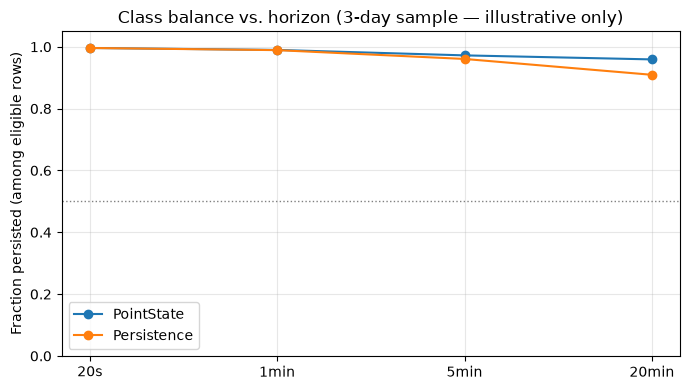

In [6]:
rows = []

for target_name, builder in [ #Here, we iterate over each target type and its corresponding builder function
    ("PointState",  build_point_state_target),
    ("Persistence", build_persistence_target),
]:
    for h_name, h_bins in HORIZONS.items(): #Iterate over each horizon and its corresponding number of bins
        tdf = builder(state_per_bin, h_bins) #Build the target DataFrame for the current horizon
        n_total = len(tdf) #Total number of bins
        n_valid = int(tdf["target_valid"].sum()) #Number of valid target rows
        pos = int((tdf.loc[tdf["target_valid"], "target"] == 1).sum()) #Number of positive (persisted) targets
        neg = int((tdf.loc[tdf["target_valid"], "target"] == 0).sum()) #Number of negative (dissolved) targets
        pfrac = pos / n_valid if n_valid else np.nan #Fraction of positive targets among valid rows
        rows.append(
            {
                "target":           target_name, # Name of the target type (PointState or Persistence)
                "horizon":          h_name, # Horizon label (e.g., "20s", "1min", "5min", "20min")
                "n_total_bins":     n_total, # Total number of bins for this horizon
                "n_valid":          n_valid, # Number of valid target rows
                "n_dropped":        n_total - n_valid, # Number of dropped (invalid) rows
                "n_persisted":      pos, # Number of positive (persisted) targets
                "n_dissolved":      neg, # Number of negative (dissolved) targets
                "p_persisted":      pfrac, # Fraction of positive targets among valid rows
                "naive_baseline":   max(pfrac, 1 - pfrac) if n_valid else np.nan, # Naive baseline accuracy (majority class)
            }
        )

summary = pd.DataFrame(rows)
display(summary.round(4))

# How much does each day contribute (shown for 5-min horizon)?
print("\nPer-day eligible-row counts (5-min horizon):")
for target_name, builder in [
    ("PointState",  build_point_state_target),
    ("Persistence", build_persistence_target),
]:
    tdf = builder(state_per_bin, HORIZONS["5min"])
    tdf = tdf.loc[tdf["target_valid"]].copy()
    tdf["date"] = tdf.index.normalize().date
    print(f"  {target_name}: {tdf.groupby('date').size().to_dict()}")

# Positive fraction vs. horizon
fig, ax = plt.subplots(figsize=(7, 4))
for target_name in ["PointState", "Persistence"]:
    sub = summary[summary["target"] == target_name]
    ax.plot(sub["horizon"], sub["p_persisted"], marker="o", label=target_name)
ax.axhline(0.5, color="gray", linestyle=":", linewidth=1)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Fraction persisted (among eligible rows)")
ax.set_title("Class balance vs. horizon (3-day sample — illustrative only)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

### Interpretation

- Note that Persistence can never exceed PointState, since "every bin cloudy" implies "bin t+h cloudy". 
- At 20s the two targets are identical, because there is only one future bin. 
- The gap grows with horizon. At 20 min, 8544 rows are cloudy at t+h, but only 8.090 stay cloudy throughout. 
- Therefore, Persistence is the stricter and more informative target at longer horizons. It also captures the flickering that the EDA's many short runs would predict. 

Also note, we have **limited number of events**. There are only 34 dissolved rows at the 20 s horizon, and they come from about 34 cloudy runs. 

## 5. Alignment Plots

For a chosen horizon (5 min here), we can show one timestamp where the cloud **dissipates** and one where it **persists**. This is the best way to confirm the target rows align with what we mean visually. 

If no dissolution example exists at the chosen horizon, we can build a fallback to the first valid row. 

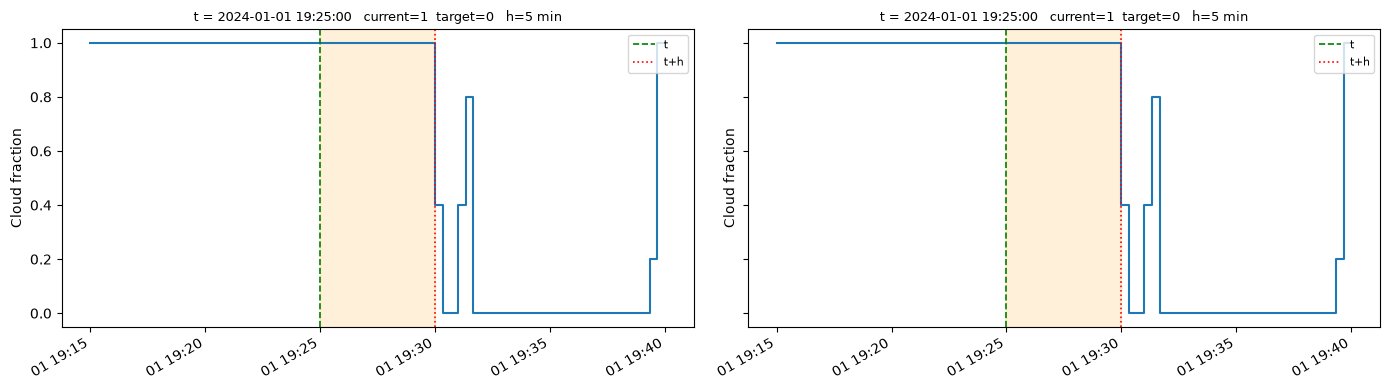

In [8]:
#Define a function to plot the alignment of cloud observations and target predictions
def plot_alignment(ax, bins, target_df, t_example, h_seconds, title_suffix=""):
    t_end = t_example + pd.Timedelta(seconds=h_seconds)
    t_start = t_example - pd.Timedelta(minutes=10) # Start of the plotting window (10 minutes before the example time)
    t_stop  = t_end     + pd.Timedelta(minutes=10) # End of the plotting window (10 minutes after the target time)

    window = bins.loc[t_start:t_stop]
    ax.step(window.index, window["cloud_fraction"], where="post", color="tab:blue") # Plot cloud fraction as a step plot
    ax.axvspan(t_example, t_end, alpha=0.15, color="orange") # Highlight the target prediction window
    ax.axvline(t_example, color="green", linestyle="--", linewidth=1.2, label="t") # Mark the example time
    ax.axvline(t_end,     color="red",   linestyle=":",  linewidth=1.2, label="t+h") # Mark the end of the prediction horizon

    cur = int(target_df.loc[t_example, "current_state"]) # Current cloud state at the example time
    tgt = int(target_df.loc[t_example, "target"]) # Target prediction at the example time
    ax.set_ylim(-0.05, 1.05) # Set y-axis limits for cloud fraction
    ax.set_ylabel("Cloud fraction") # Label for y-axis
    ax.set_title(
        f"t = {t_example}   current={cur}  target={tgt}   "
        f"h={h_seconds//60} min{title_suffix}", fontsize=9 # Title showing example time, current state, target, and horizon
    )
    ax.legend(loc="upper right", fontsize=8) # Legend for the plot


H_LABEL = "5min"
H_BINS  = HORIZONS[H_LABEL]
H_SECONDS = H_BINS * INTERVAL_SECONDS

#Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, target_name, builder in [
    (axes[0], "PointState",  build_point_state_target),
    (axes[1], "Persistence", build_persistence_target),
]:
    tdf = builder(state_per_bin, H_BINS)
    valid = tdf.loc[tdf["target_valid"]]
    if valid.empty:
        ax.text(0.5, 0.5, "No valid rows", transform=ax.transAxes, ha="center")
        ax.set_title(target_name)
        continue

    # Prefer a dissolution example if one exists
    dissolved = valid[valid["target"] == 0]
    if not dissolved.empty:
        t_example = dissolved.index[0]
        suffix = ""
    else:
        t_example = valid.index[0]
        suffix = "   (no dissolution in sample)"

    plot_alignment(ax, bins, tdf, t_example, H_SECONDS, suffix)

for ax in axes:
    for lbl in ax.get_xticklabels():
        lbl.set_rotation(30)
        lbl.set_horizontalalignment("right")
plt.tight_layout()
plt.show()

## Conclusion & Next Steps

We immediately can conclude that the 20 s horizon is trivial and should not be used for modeling. Furthermore, 
- The 5 min and 20 min horizons are the most informative candidates. We can choose once we run the entire year. 
- **Persistence is the preferred target** because it aviods counting a cloud that broke and re-formed as persisting. 
- The next step is to run this sketch over all of 2024, one day at a time and carrying state across midnight. We can then look at class balance. 